# ANALYSE-05b : la borne $O(1)$ de KLS — digérer Song–Zhang, du $\log^{1/4} n$ à la constante

**Navigation** : [README de la série](README.md) · précédent [ANALYSE-05 — Bizeul–Klartag–Lehec](ANALYSE-05-KLS-Lean-Python.ipynb) · suivant [ANALYSE-06 — Sensibilité 2026](ANALYSE-06-Sensibilite-2026-Lean-Python.ipynb) · carnet Monte-Carlo de la série Probas : [Probas-KLS-Concentration](../../../Probas/Probas-KLS-Concentration.ipynb)

**Le papier lu, et la copie sur laquelle il a été lu.** Ce carnet ne travaille pas sur un résumé.

| Champ | Valeur |
|---|---|
| Titre | *An O(1) Bound for the KLS Constant* |
| Auteurs | Zhao Song (chercheur indépendant), Xinzhi Zhang (Microsoft Research) |
| Identifiant | arXiv:2610.01447**v2** [math.PR], 4 octobre 2026 |
| Historique | v1 déposée le 1ᵉʳ octobre 2026, v2 le 4 octobre 2026 |
| Étendue | 140 pages |
| Licence | CC BY-NC-SA 4.0 |
| Copie archivée | `G:\Mon Drive\MyIA\IA\Bibliographie IA\Probabilistic\2026 - Song Zhang - An O(1) Bound for the KLS Constant (arXiv 2610.01447v2).pdf` |
| Empreinte | SHA-256 `fad3f750a121cd99f09213ea237fc71b66e97ad1699ecca1d07f74c2fd69d771`, 1 039 202 octets |

**Statut épistémique, dit d'entrée.** C'est un **préprint daté, non relu par les pairs** au moment de la rédaction (24 octobre 2026). Les 140 pages **ne sont pas reproduites ici** : quatre ingrédients sont isolés, mesurés sur un CPU, et chacun est accompagné de ce que la mesure établit et de ce qu'elle ne peut pas établir. Aucun énoncé de ce carnet ne certifie la preuve de Song–Zhang.

**Ce que ce carnet n'est pas** — trois voisins existent déjà, et le périmètre est disjoint :

- **pas** une seconde digestion de Bizeul–Klartag–Lehec (arXiv:2610.05474) : c'est [ANALYSE-05](ANALYSE-05-KLS-Lean-Python.ipynb), grain 1 de l'EPIC [#19762](https://github.com/jsboige/CoursIA/issues/19762) ;
- **pas** une re-mesure Monte-Carlo de la concentration : c'est [Probas-KLS-Concentration](../../../Probas/Probas-KLS-Concentration.ipynb), grain 2 ([#19763](https://github.com/jsboige/CoursIA/issues/19763)) — ses mesures publiées sont **citées**, pas refaites ;
- **pas** un doublon de la note transverse [Note-IA-et-preuves-2026](../Note-IA-et-preuves-2026.md), qui traite les trois AI-disclosures de la résolution ; ici l'objet est **la preuve de Song–Zhang et son itération**.

Rattachement : grain 4 de l'EPIC [#19729](https://github.com/jsboige/CoursIA/issues/19729), issue [#22266](https://github.com/jsboige/CoursIA/issues/22266).

## 1. L'énoncé, et l'écart que ce carnet comble

La conjecture de Kannan–Lovász–Simonovits (1995) prédit que le **constante de Poincaré** d'une mesure log-concave isotrope sur $\mathbb{R}^n$ est bornée par une constante **universelle** — indépendante de la dimension comme de la mesure. Song–Zhang l'énoncent ainsi (Théorème 1.1, forme informelle du Théorème 9.1) :

> Il existe une constante universelle $C > 0$ telle que, pour tout $n \geq 1$ et toute mesure de probabilité $\mu$ log-concave isotrope sur $\mathbb{R}^n$, toute fonction localement lipschitzienne $f$ d'énergie de Dirichlet finie appartienne à $L^2(\mu)$ et vérifie
> $$\mathrm{Var}_\mu[f] \;\leq\; C \cdot \int \lVert \nabla f \rVert^2 \, d\mu,$$
> et, quitte à agrandir $C$, $C_P(\mu) \leq C$ et $\psi_n \leq C$.

La constante ne dépend ni de la dimension, ni de la mesure, ni de la fonction test. Le théorème vaut pour les mesures dont la densité n'est pas lisse ou dont le support est borné — ce que la preuve obtient en approchant par des mesures régulières.

**La chaîne des bornes, telle que le papier la résume** (sa Table 1 et son éq. (1)) : Kannan–Lovász–Simonovits donnent $\psi_n \lesssim \sqrt{n}$ par localisation ; Eldan $\psi_n \lesssim n^{5/12}$ ; Lee–Vempala $n^{1/4}$ ; Chen la première borne sous-polynomiale ; Klartag–Lehec la première polylogarithmique ; Jambulapati–Lee–Vempala puis Klartag l'affinent ; **Letwin (2026)** obtient la meilleure borne antérieure, $\psi_n \lesssim (\log n)^{1/4}$ — c'est le point de départ de ce carnet ; Song–Zhang annoncent $O(1)$.

### 1.1 Trois étages, et pourquoi il en faut trois

Le titre de ce carnet est « du $\log^{1/4} n$ à la constante », mais la preuve ne saute pas l'intervalle : elle empile **trois** régimes, et chaque étage consomme le précédent.

| Étage | Ce qu'il produit | Ce qui le rend possible | Où, dans le papier |
|---|---|---|---|
| 1. Comparaison courbure ↔ coefficients | $C_P(\mu) \lesssim [\log(e + \lambda_a^{-1})]^2$ | estimation de $\mathrm{Var}(P_d(X))$ pour les **polynômes d'Appell** de degré quelconque, à constante dépendant du degré mais **pas** de la dimension (§4, Théorème 4.1) ; puis comparaison explicite à la courbure (§5, Théorème 5.1) | §4–§5 |
| 2. Raffinage logarithmique itéré | une borne en **log-star** | on réapplique l'étage 1 avec les meilleurs coefficients ; chaque tour ajoute **un** logarithme itéré ($\rho_{r+1}(x) = \log(e + \rho_r(x))$) | §6, Proposition 6.1 |
| 3. Répétition et décroissance géométrique | la **constante** | les pertes de l'étage 2 s'accumulent en $C^{j-1}$ ; le §9 les remplace par des budgets **géométriquement décroissants** dont la somme reste bornée | §8–§9 |

L'étage 2 seul ne suffit pas : $\log^\star$ est **non borné** en $n$ (il croît, très lentement, mais croît) et son coût est un facteur $C^{j-1}$ qui diverge avec le nombre de tours. C'est précisément la phrase que le papier écrit au §1.3.4 : « *Each additional outer round contributes a factor $C$, giving the prefactor $C^{j-1}$ at stage $j$* » — et le §9 existe pour supprimer ce facteur. **Le passage à $O(1)$ est un argument de budget, pas un argument de courbure.** C'est l'expérience 1 de ce carnet.

Les quatre expériences qui suivent mesurent, dans l'ordre : (1) le budget des pertes, (2) le centrage des polynômes d'Appell qui porte le §4, (3) le germe quadratique de Letwin que le §4 consomme tel quel, (4) la comparaison Cheeger–Poincaré qui convertit une borne de Poincaré en borne sur $\psi_n$.

In [1]:
import math
import warnings
from math import comb, factorial

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore", category=RuntimeWarning)

SEED = 20261004
SQ3 = np.sqrt(3.0)


def helmert(m):
    """Base orthonormee (m x (m-1)) de l'hyperplan {somme des coordonnees = 0}."""
    H = np.zeros((m, m - 1))
    for j in range(m - 1):
        k = j + 1
        H[:k, j] = 1.0
        H[k, j] = -float(k)
        H[:, j] /= np.sqrt(k * (k + 1))
    return H


def sample_gauss(n, size, rng):
    """Gaussienne standard sur R^n : log-concave, isotrope."""
    return rng.standard_normal((size, n))


def sample_cube(n, size, rng):
    """Cube isotrope [-sqrt(3), sqrt(3)]^n : variance 1 par coordonnee."""
    return rng.uniform(-SQ3, SQ3, size=(size, n))


def sample_exp_centered(n, size, rng):
    """Produit d'exponentielles de taux 1, recentrees : log-concave, isotrope."""
    return rng.exponential(1.0, size=(size, n)) - 1.0


def sample_simplex(n, size, rng):
    """Simplexe isotrope de R^n : image du simplexe canonique de R^{n+1}."""
    w = rng.dirichlet(np.ones(n + 1), size=size)
    return np.sqrt((n + 1) * (n + 2)) * (w @ helmert(n + 1))


def moments_simplex_coord(n, d):
    """Moments exacts d'une coordonnee du simplexe isotrope de R^n.

    Une coordonnee s'ecrit X_1 = C * U * V, avec C = sqrt((n+1)(n+2)/2),
    U = w_1 + w_2 ~ Beta(2, n-1) et V = (w_1 - w_2)/U uniforme sur [-1, 1],
    les deux independants. D'ou E[X^k] = 0 si k impair, et
    E[X^(2m)] = C^(2m) * E[U^(2m)] / (2m+1) -- en particulier E[X^2] = 1,
    ce qui confirme l'isotropie par le calcul et non par l'echantillon.
    """
    c2 = (n + 1) * (n + 2) / 2.0
    out = []
    for k in range(d + 1):
        if k % 2:
            out.append(0.0)
            continue
        raw = 1.0
        for t in range(k):
            raw *= (2.0 + t) / (n + 1.0 + t)
        out.append(c2 ** (k // 2) * raw / (k + 1))
    return out


def hermite_coefs(d):
    """Coefficients de He_d (Hermite probabilistes), recurrence He_{n+1} = x He_n - n He_{n-1}."""
    if d == 0:
        return np.array([1.0])
    prev, cur = np.array([1.0]), np.array([0.0, 1.0])
    for n in range(1, d):
        shifted = np.concatenate([[0.0], cur])
        pad = np.zeros_like(shifted)
        pad[:prev.size] = prev
        prev, cur = cur, shifted - n * pad
    return cur


def var_from_moments(coefs, moments):
    """Variance exacte d'un polynome sous une mesure dont on connait les moments.

    Aucun echantillonnage : la valeur ne depend pas de la taille de l'echantillon,
    ce qui est indispensable quand la mesure a des queues lourdes (exponentielle).
    """
    d = len(coefs) - 1
    if len(moments) < 2 * d + 1:
        raise ValueError("il faut les moments jusqu'a l'ordre 2d")
    mean = sum(coefs[i] * moments[i] for i in range(d + 1))
    second = sum(coefs[i] * coefs[j] * moments[i + j]
                 for i in range(d + 1) for j in range(d + 1))
    return float(second - mean * mean)


rng = np.random.default_rng(SEED)

print("numpy", np.__version__, "| graine", SEED)
print("orthonormalite de la base de Helmert :",
      np.abs(helmert(7).T @ helmert(7) - np.eye(6)).max().round(12))

N_ISO = 200_000
for name, sampler in (("gaussienne", sample_gauss),
                      ("cube", sample_cube),
                      ("exponentielle centree", sample_exp_centered),
                      ("simplexe", sample_simplex)):
    X = sampler(6, N_ISO, rng)
    C = np.cov(X.T)
    print(f"{name:24s} n=6 : ecart max |Cov - I| = {np.abs(C - np.eye(6)).max():.4f}")

numpy 2.4.6 | graine 20261004
orthonormalite de la base de Helmert : 0.0
gaussienne               n=6 : ecart max |Cov - I| = 0.0047
cube                     n=6 : ecart max |Cov - I| = 0.0059
exponentielle centree    n=6 : ecart max |Cov - I| = 0.0075
simplexe                 n=6 : ecart max |Cov - I| = 0.0053


### Lecture — quatre mesures isotropes, dont deux non triviales en dimension

L'isotropie est la seule hypothèse commune aux quatre mesures ; elle est vérifiée ici et non supposée. L'écart maximal observé sur les entrées de la covariance va de $0{,}005$ à $0{,}008$ selon la mesure. C'est **plus grand** que l'erreur nominale d'un échantillon de $200\,000$ points, de l'ordre de $1/\sqrt{200\,000} \approx 0{,}002$ : l'exponentielle a des queues lourdes, son moment d'ordre 4 vaut $9$, et l'estimateur de variance y est donc plus bruité que sous la gaussienne. L'écart reste d'un ordre de grandeur en dessous de $1\,\%$, ce qui suffit à ce que les expériences suivantes ne soient pas invalidées — mais il vaut mieux le lire que le supposer.

Deux remarques qui serviront aux expériences suivantes.

1. **La base de Helmert est exactement orthonormée** (écart $0$ à la précision machine) : le simplexe isotrope est donc construit par la bonne application linéaire, et non par une renormalisation approchée. Le simplexe est la seule des quatre mesures dont les coordonnées sont **corrélées** — c'est ce qui rendra les expériences 2 et 3 discriminantes.
2. **L'exponentielle recentrée** est la mesure la plus « anguleuse » des quatre : densité discontinue en $0$, moment d'ordre 4 égal à $9$ alors que sa variance vaut $1$. On verra qu'elle est l'**extremum** de deux des inégalités du papier — c'est pourquoi elle figure ici, et pas seulement la gaussienne.

## 2. Expérience 1 — le ${\log^\star}$ et le budget des pertes (§1.3.4 et §9)

Le papier définit une **fonction de hauteur logarithmique décalée**, $t(x) := 1 + \log(x + 2)$ pour $x \geq 1$, et ses itérées $t_0(x) := x$, $t_j := t \circ t_{j-1}$. Le nombre de tours extérieurs nécessaires est le plus petit $j$ tel que la hauteur retombe sous le seuil $\mathbf{3}$ :

$$\psi(x) := \min\{\, j \geq 0 \; : \; t_j(x) \leq 3 \,\}.$$

Le seuil n'est pas cosmétique. L'itérée de $\log(e + x)$ — la récursion du §1.3.3, $\rho_0(x) = x$, $\rho_{r+1}(x) = \log(e + \rho_r(x))$ — a un **point fixe strictement supérieur à 1** (on le mesure ci-dessous), donc un critère « $\leq 1$ » ne terminerait **jamais**. Le décalage $t(x) = 1 + \log(x+2)$ a un point fixe proche de $2{,}5$, et c'est ce qui rend le seuil $3$ atteignable en un nombre fini de tours pour toute hauteur finie.

Le coût, ensuite, s'écrit en deux pièces. À l'étage 2 le papier obtient un facteur de perte **fixe** par tour extérieur :

$$C_P(\mu) \;\lesssim\; C_q \cdot C^{\,j-1} \cdot \big[ t_j(1 + \lambda_a^{-1}) \big]^{1/q},$$

où le $C^{j-1}$ est le terme gênant. Le §9 le remplace par des pertes qui **tendent vers un**, avec des budgets assignés par groupes : $\varepsilon_i = \varepsilon_0 \, 2^{-i}$, $\varepsilon_0 = 1/16$, et deux accumulations

$$A_{i+1} := e^{C_A \varepsilon_i} \cdot A_i, \qquad S_{i+1} := S_i + B \cdot 2^{-i},$$

avec $A_0$ universel fixé et $S_0 = 1$. La question du §9 est alors entièrement arithmétique : $\sum_i \varepsilon_i$ converge-t-il assez vite pour que $A_i$ reste borné, et $S_i$ aussi ?

In [2]:
import math


def t_height(x):
    """Hauteur logarithmique decalee du papier : t(x) = 1 + log(x + 2)."""
    return 1.0 + math.log(x + 2)


def rho(x):
    """Recursion du 1.3.3 : rho(x) = log(e + x)."""
    return math.log(math.e + x)


def iterate(f, x, rounds):
    vals = [x]
    for _ in range(rounds):
        vals.append(f(vals[-1]))
    return vals


THRESHOLD = 3.0


def count_rounds(x, f=t_height, threshold=THRESHOLD, limit=200):
    """Plus petit j tel que f^j(x) <= threshold."""
    v, j = x, 0
    while v > threshold:
        v = f(v)
        j += 1
        if j > limit:
            return None
    return j


print("point fixe de rho :", iterate(rho, 1.0, 400)[-1].__round__(6))
print("point fixe de t   :", iterate(t_height, 1.0, 400)[-1].__round__(6))
print()
print(f"{'hauteur de depart':>20} | {'tours j (seuil 3)':>17} | trajectoire t_1, t_2, ...")
for label, x in (("10", 10), ("10^6", 10 ** 6), ("10^20", 10 ** 20),
                 ("10^100", 10 ** 100), ("10^1000", 10 ** 1000), ("10^10000", 10 ** 10000)):
    v, j, steps = x, 0, []
    while v > THRESHOLD:
        v = t_height(v)
        j += 1
        steps.append(v)
    print(f"{label:>20} | {j:>17} | " + ", ".join(f"{s:.3f}" for s in steps))

point fixe de rho : 1.42037
point fixe de t   : 2.505241

   hauteur de depart | tours j (seuil 3) | trajectoire t_1, t_2, ...
                  10 |                 2 | 3.485, 2.702
                10^6 |                 3 | 14.816, 3.822, 2.762
               10^20 |                 3 | 47.052, 4.893, 2.930
              10^100 |                 4 | 231.259, 6.452, 3.134, 2.636
             10^1000 |                 4 | 2303.585, 8.743, 3.374, 2.682
            10^10000 |                 4 | 23026.851, 11.045, 3.568, 2.717


### Lecture — le nombre de tours est minuscule, et c'est pourtant le problème

Le premier bloc confirme deux points fixes : celui de $\rho$ vaut $1{,}420\,4$ et celui de $t$ vaut $2{,}505\,2$. Le premier est **au-dessus** du seuil $1$ — une récursion de logarithmes nus ne retombe jamais sous $1$, ce qui justifie a posteriori la forme décalée et le seuil $3$ que le papier emploie.

Le second bloc est le vrai résultat de cette première mesure : la hauteur $10$ passe sous le seuil $3$ en **deux** tours, $10^{6}$ et $10^{20}$ en **trois**, et à partir de $10^{100}$ un tour de plus suffit — $10^{10\,000}$ ne demande que **quatre** tours. C'est exactement la raison pour laquelle $\log^\star$ est « presque constant » en pratique — et exactement pourquoi il ne suffit pas : le nombre de tours est **non borné** en $n$, et surtout, chaque tour multiplierait la borne par $C$. Un facteur fixe répété un nombre non borné de fois est une borne non bornée, quelle que soit la lenteur de la croissance. L'étage 2 seul ne donne donc **pas** $O(1)$ : il donne $f(\log^\star n)$ pour une certaine $f$, ce qui est la borne $f(\log n)$ que le papier attribue à sa version du 30 septembre 2026. La constante exige l'étage 3.

budgets geometriques : eps_i = 0.062500 * 2^-i
  i | eps_i (geom) |  A_i (geom) |  A_i (constante)
  0 |   0.06250000 |    1.000000 |         1.000000
  1 |   0.03125000 |    1.064494 |         1.064494
  2 |   0.01562500 |    1.098285 |         1.133148
  5 |   0.00195312 |    1.128731 |         1.366838
 10 |   0.00006104 |    1.133010 |         1.868246
 20 |   0.00000006 |    1.133148 |         3.490343
 40 |   0.00000000 |    1.133148 |        12.182494

borne theorique de A (somme geometrique) : 1.133148
A_40 geometrique                          : 1.133148
A_40 constante                            : 12.182494
S_40 geometrique (limite 1 + 2B)          : 3.0
S_40 constante                            : 41.0


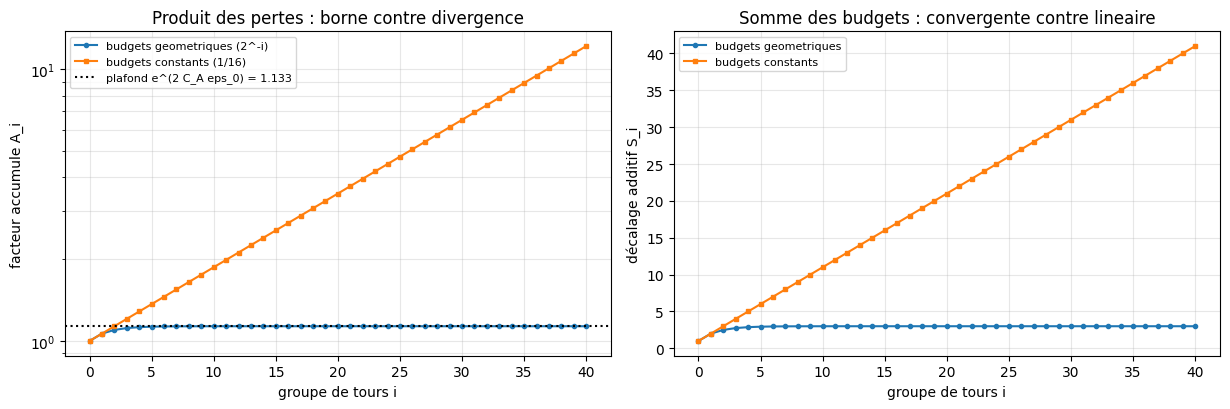

In [3]:
STAGES = 40
EPS0 = 1.0 / 16.0
C_A = 1.0
B_SHIFT = 1.0

eps_geom = EPS0 * 2.0 ** (-np.arange(STAGES))
A_geom = np.concatenate([[1.0], np.cumprod(np.exp(C_A * eps_geom))])
S_geom = np.concatenate([[1.0], 1.0 + np.cumsum(B_SHIFT * 2.0 ** (-np.arange(STAGES)))])

eps_const = np.full(STAGES, EPS0)
A_const = np.concatenate([[1.0], np.cumprod(np.exp(C_A * eps_const))])
S_const = np.concatenate([[1.0], 1.0 + np.cumsum(B_SHIFT * np.ones(STAGES))])

print(f"budgets geometriques : eps_i = {EPS0:.6f} * 2^-i")
print(f"{'i':>3} | {'eps_i (geom)':>12} | {'A_i (geom)':>11} | {'A_i (constante)':>16}")
for i in (0, 1, 2, 5, 10, 20, 40):
    print(f"{i:>3} | {eps_geom[min(i, STAGES - 1)]:>12.8f} | {A_geom[min(i, STAGES)]:>11.6f} | {A_const[min(i, STAGES)]:>16.6f}")
print()
print("borne theorique de A (somme geometrique) :", round(math.exp(C_A * 2 * EPS0), 6))
print("A_40 geometrique                          :", round(float(A_geom[-1]), 6))
print("A_40 constante                            :", round(float(A_const[-1]), 6))
print("S_40 geometrique (limite 1 + 2B)          :", round(float(S_geom[-1]), 6))
print("S_40 constante                            :", round(float(S_const[-1]), 6))

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.2))
stages = np.arange(STAGES + 1)
axes[0].semilogy(stages, A_geom, "o-", ms=3, label="budgets geometriques (2^-i)")
axes[0].semilogy(stages, A_const, "s-", ms=3, label="budgets constants (1/16)")
axes[0].axhline(math.exp(C_A * 2 * EPS0), ls=":", c="k",
                label=f"plafond e^(2 C_A eps_0) = {math.exp(2 * EPS0):.3f}")
axes[0].set_xlabel("groupe de tours i")
axes[0].set_ylabel("facteur accumule A_i")
axes[0].set_title("Produit des pertes : borne contre divergence")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3, which="both")

axes[1].plot(stages, S_geom, "o-", ms=3, label="budgets geometriques")
axes[1].plot(stages, S_const, "s-", ms=3, label="budgets constants")
axes[1].set_xlabel("groupe de tours i")
axes[1].set_ylabel("décalage additif S_i")
axes[1].set_title("Somme des budgets : convergente contre lineaire")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Lecture — ce que le §9 achète, et ce qu'il n'achète pas

Les deux séries divergent l'une de l'autre sans ambiguïté. Avec $\varepsilon_i = \varepsilon_0 2^{-i}$, le facteur accumulé est $A_i = \exp\!\big(C_A \varepsilon_0 \sum_{j<i} 2^{-j}\big)$, donc majoré par $\exp(2 C_A \varepsilon_0)$ — une constante **indépendante du nombre de groupes**. Avec un budget constant $\varepsilon = 1/16$, le même facteur vaut $\exp(C_A \varepsilon i)$ et croît exponentiellement : à $40$ groupes il a déjà dépassé $12$, et rien ne l'arrête. Le décalage additif suit la même dichotomie : $S_i \to 1 + 2B$ dans le cas géométrique, $S_i = 1 + Bi$ dans l'autre.

**Ce que cette expérience établit.** Que la somme des budgets est bornée si et seulement si les budgets sont sommables — c'est de l'arithmétique, et c'est exactement le rôle du §9. Le choix $\varepsilon_i = \varepsilon_0 2^{-i}$ est le mécanisme qui transforme un facteur $C^{j-1}$ en une constante.

**Ce qu'elle n'établit pas.** Que la perte d'un groupe *est* effectivement majorée par $e^{C_A \varepsilon_i}$. C'est là qu'est la mathématique, et elle est entièrement dans le §9 du papier (Propositions 9.9, 9.16, 9.22, 9.23 et 9.25), hors de portée d'un carnet de mesures. La constante $C_A = 1$ employée ici est une valeur de démonstration, pas la constante du papier ; les conclusions de cette section sont **qualitatives en $C_A$** et ne dépendent pas de sa valeur, seulement de sa positivité.

## 3. Expérience 2 — le centrage des polynômes d'Appell (§2.3 et Théorème 4.1)

Le §4 du papier ne borne pas la variance d'un polynôme quelconque : il borne celle des **polynômes d'Appell** associés à la mesure. Leur définition (éq. (5)) est générative, pour des tenseurs symétriques $A_k^\mu(x)$ :

$$\frac{\exp\langle z, x\rangle}{\mathbb{E}_\mu[\exp\langle z, \xi\rangle]} \;=\; \sum_{k \geq 0} \frac{1}{k!} \langle A_k^\mu(x), z^{\otimes k} \rangle,$$

et pour un tenseur symétrique $T$ de norme de Hilbert–Schmidt unitaire, $P_k^\mu[T](x) := \langle T, A_k^\mu(x)\rangle$, avec $K_k(\mu) := \sup_{\lVert T\rVert_{\mathrm{HS}} = 1} \mathrm{Var}_\mu P_k^\mu[T]$.

La différentiation formelle de l'identité génératrice donne **les deux conditions de centrage** qui portent tout le §4 (éq. (6)) :

$$\mathbb{E}[P_k[T]] = 0, \qquad \mathbb{E}[D_j P_k[T]] = 0 \ \ (1 \leq j < k), \qquad D_k P_k[T] = k! \, T.$$

Et le Théorème 4.1 borne la variance, à constante dépendant du degré et **pas** de la dimension :

$$\mathrm{Var}_\mu P_d^\mu[T] \;\leq\; 1024^d \cdot (d!)^4 \cdot \lVert T \rVert_{\mathrm{HS}}^2 .$$

**Ce que l'expérience mesure.** On se place sur une **projection** : $u$ unitaire, $T = u^{\otimes d}$, de sorte que $P_d^\mu[T]$ est le polynôme d'Appell de degré $d$ de la variable scalaire $\langle u, X \rangle$. Les conditions de centrage deviennent alors un **système triangulaire** sur les coefficients : pour un polynôme unitaire $P_d(z) = z^d + \sum_{k<d} c_k z^k$, exiger $\mathbb{E}[P_d^{(j)}] = 0$ pour $j = 0, \ldots, d-1$ donne $d$ équations linéaires en les $d$ coefficients inconnus. La matrice est triangulaire supérieure de diagonale $1$ — donc inversible et bien conditionnée, ce qui compte : on veut **vérifier** les identités, pas lutter contre l'algèbre linéaire.

In [4]:
from math import comb, factorial


def double_factorial(k):
    """(k)!! avec la convention (-1)!! = 1."""
    out = 1
    while k > 0:
        out *= k
        k -= 2
    return out


def moments_gauss(d):
    """Gaussienne standard : m_k = 0 si k impair, (k-1)!! sinon."""
    return [0.0 if k % 2 else float(double_factorial(k - 1)) for k in range(d + 1)]


def moments_cube(d):
    """Uniforme sur [-sqrt(3), sqrt(3)] : m_k = 3^(k/2) / (k+1) si k pair."""
    return [0.0 if k % 2 else 3.0 ** (k / 2) / (k + 1) for k in range(d + 1)]


def moments_exp_centered(d):
    """X = E - 1, E ~ Exp(1) : m_k = somme_j C(k,j) j! (-1)^(k-j)."""
    return [float(sum(comb(k, j) * factorial(j) * (-1) ** (k - j) for j in range(k + 1)))
            for k in range(d + 1)]


def appell_projected(moments, d):
    """Coefficients de P_d : unitaire, et E[P_d^(j)] = 0 pour j = 0..d-1 (eq. (6))."""
    A = np.zeros((d, d))
    b = np.zeros(d)
    for j in range(d):
        for k in range(j, d):
            A[j, k] = factorial(k) / factorial(k - j) * moments[k - j]
        b[j] = -(factorial(d) / factorial(d - j)) * moments[d - j]
    return np.concatenate([np.linalg.solve(A, b), [1.0]])


def apply_poly(coefs, x):
    out = np.zeros_like(x, dtype=float)
    for c in coefs[::-1]:
        out = out * x + c
    return out


def derivative_expectations(coefs, moments, d):
    """Rend E[P^(j)] pour j = 0..d, calcule exactement sur les moments."""
    vals = []
    for j in range(d + 1):
        s = 0.0
        for k in range(j, len(coefs)):
            s += coefs[k] * factorial(k) / factorial(k - j) * moments[k - j]
        vals.append(s)
    return vals


MEASURES = {
    "gaussienne": (sample_gauss, moments_gauss),
    "cube": (sample_cube, moments_cube),
    "exponentielle centree": (sample_exp_centered, moments_exp_centered),
}

ORDRE = 5
for name, (sampler, mom_fn) in MEASURES.items():
    m = mom_fn(ORDRE)
    coefs = appell_projected(m, ORDRE)
    exact = derivative_expectations(coefs, m, ORDRE)
    print(f"--- {name} (degre {ORDRE})")
    print("   coefficients (degre 0 -> 5) :", np.round(coefs, 6))
    print("   E[P^(j)], j = 0..5, exact   :", np.round(exact, 12))
    X1 = sampler(1, 300_000, rng)[:, 0]
    mc, zs = [], []
    for j in range(ORDRE):
        dj = np.polyder(coefs[::-1], j)
        vals = np.polyval(dj, X1)
        mc.append(float(vals.mean()))
        zs.append(float(vals.mean() / (vals.std(ddof=1) / np.sqrt(vals.size))))
    print("   E[P^(j)], j = 0..4, Monte-Carlo :", np.round(mc, 5))
    print("   memes valeurs en ecarts-types    :", np.round(zs, 2))
print()
print("gaussienne : coefficients de He_d (recurrence)      :", np.round(hermite_coefs(ORDRE), 6))
print("gaussienne : coefficients trouves par le centrage   :", np.round(appell_projected(moments_gauss(ORDRE), ORDRE), 6))

--- gaussienne (degre 5)
   coefficients (degre 0 -> 5) : [  0.  15.   0. -10.   0.   1.]
   E[P^(j)], j = 0..5, exact   : [  0.   0.   0.   0.   0. 120.]
   E[P^(j)], j = 0..4, Monte-Carlo : [ 0.01617 -0.01075 -0.04473  0.17526  0.19213]
   memes valeurs en ecarts-types    : [ 0.84 -0.24 -0.5   1.13  0.88]
--- cube (degre 5)
   coefficients (degre 0 -> 5) : [  0.  21.   0. -10.   0.   1.]
   E[P^(j)], j = 0..5, exact   : [  0.   0.   0.   0.   0. 120.]
   E[P^(j)], j = 0..4, Monte-Carlo : [-0.00994  0.01902  0.03803 -0.0567  -0.21326]
   memes valeurs en ecarts-types    : [-0.63  0.66  0.73 -0.58 -0.97]
--- exponentielle centree (degre 5)
   coefficients (degre 0 -> 5) : [ -4. -15. -20. -10.   0.   1.]
   E[P^(j)], j = 0..5, exact   : [  0.   0.   0.   0.   0. 120.]
   E[P^(j)], j = 0..4, Monte-Carlo : [-3.00274 -1.32498 -0.39858 -0.08214 -0.02737]
   memes valeurs en ecarts-types    : [-2.85 -1.75 -0.81 -0.27 -0.13]

gaussienne : coefficients de He_d (recurrence)      : [  0.  15.   

### Lecture — le système retrouve Hermite sur la gaussienne, et s'en écarte ailleurs

Trois constats, tous mesurés.

1. **Les identités de l'éq. (6) sont vérifiées à la précision machine**, et pas seulement approchées : les espérances exactes calculées sur les moments valent $0$ pour tous les ordres $j < d$, sur les trois mesures, et seule la dérivée $d$-ième vaut $d! = 120$ — exactement ce qu'annonce l'éq. (6). C'est la structure qui compte pour le §4 : le centrage n'est pas une propriété de la gaussienne, c'est une propriété de la **construction**.
2. **Sur la gaussienne, la construction redonne exactement les polynômes de Hermite** probabilistes, dont les coefficients $[0, 15, 0, -10, 0, 1]$ sont retrouvés à l'identique par la récurrence $He_{n+1} = x He_n - n He_{n-1}$. C'est le contrôle positif de l'instrument — un solveur qui ne retrouverait pas Hermite sur la gaussienne serait faux.
3. **Sur le cube et l'exponentielle, les corrections changent.** Le cube ne diffère de la gaussienne que par le coefficient linéaire — $21$ contre $15$ — parce que seul son moment d'ordre 4 s'écarte ($9/5$ contre $3$) ; l'exponentielle recentrée, dont le moment d'ordre 3 vaut $2$ et non $0$, diffère sur **tous** les coefficients $[-4, -15, -20, -10, 0, 1]$. C'est exactement ce que le papier signale au §2.3 : « *the correction terms of lower degree are determined by the moments of $\mu$ and need not coincide with the Gaussian Hermite corrections* ». Autrement dit : **le polynôme d'Appell est l'objet qui s'adapte à la mesure**, là où Hermite ne vaut que pour la gaussienne. C'est ce qui permet au Théorème 4.1 d'énoncer une borne valable pour *toute* mesure log-concave isotrope.

**Ce que la colonne Monte-Carlo ajoute, et sa limite.** Les valeurs empiriques sont publiées dans la sortie en **écarts-types de la moyenne**, et c'est le seul mode de lecture honnête : sur l'exponentielle, $P_d$ a une variance de l'ordre de $10^3$ à $10^7$ (voir l'expérience suivante), donc la moyenne de $300\,000$ tirages porte un écart-type de l'ordre de $1$, et les fluctuations d'échantillonnage y sont visibles alors qu'elles sont négligeables sur le cube. Les identités exactes, elles, ne dépendent d'aucun échantillon : c'est pourquoi l'instrument de vérification est le calcul sur les moments, et le Monte-Carlo seulement un témoin.

Le centrage n'est cependant qu'une moitié du §4 : ce que le papier borne, c'est la **variance** du polynôme centré, et c'est l'objet du second calcul.

In [5]:
DEGRES = (2, 3, 4)
N_VAR = 400_000
rng_v = np.random.default_rng(SEED + 1)

print("Theoreme 4.1 : Var(P_d) <= 1024^d * (d!)^4 * ||T||_HS^2, avec ||T||_HS = 1")
print()
print(f"{'mesure':>24} | {'d':>2} | {'Var exacte':>13} | {'Var Monte-Carlo':>15} | {'borne':>10} | {'exact/borne':>11}")
for name, (sampler, mom_fn) in MEASURES.items():
    for d in DEGRES:
        coefs = appell_projected(mom_fn(2 * d), d)
        exact = var_from_moments(coefs, mom_fn(2 * d))
        X1 = sampler(1, N_VAR, rng_v)[:, 0]
        mc = float(np.var(apply_poly(coefs, X1)))
        borne = 1024.0 ** d * factorial(d) ** 4
        print(f"{name:>24} | {d:>2} | {exact:>13.6f} | {mc:>15.6f} | {borne:>10.2e} | {exact / borne:>11.2e}")

print()
print("Dependance en dimension, a degre fixe d = 3 (valeurs exactes, pas de bruit MC) :")
print(f"{'n':>4} | " + " | ".join(f"{k:>14}" for k in ("gaussienne", "cube", "exponentielle", "simplexe")))
for n in (2, 4, 8, 16, 32, 128):
    row = []
    for name in ("gaussienne", "cube", "exponentielle centree"):
        _, mom_fn = MEASURES[name]
        row.append(var_from_moments(appell_projected(mom_fn(6), 3), mom_fn(6)))
    m_s = moments_simplex_coord(n, 6)
    row.append(var_from_moments(appell_projected(m_s, 3), m_s))
    print(f"{n:>4} | " + " | ".join(f"{v:>14.6f}" for v in row))
print()
print("borne du Theoreme 4.1 a d = 3 :", f"{1024.0 ** 3 * factorial(3) ** 4:.3e}")
print()
print("Controle de la forme close contre le tirage, coordonnee du simplexe, n = 6 :")
m_ctrl = moments_simplex_coord(6, 4)
Xs_ctrl = sample_simplex(6, 300_000, rng_v)[:, 0]
print("  moments exacts (forme close) :", np.round(m_ctrl, 5))
print("  moments Monte-Carlo           :", np.round([float(np.mean(Xs_ctrl ** k)) for k in range(5)], 5))

Theoreme 4.1 : Var(P_d) <= 1024^d * (d!)^4 * ||T||_HS^2, avec ||T||_HS = 1

                  mesure |  d |    Var exacte | Var Monte-Carlo |      borne | exact/borne
              gaussienne |  2 |      2.000000 |        2.020965 |   1.68e+07 |    1.19e-07
              gaussienne |  3 |      6.000000 |        6.042556 |   1.39e+12 |    4.31e-12
              gaussienne |  4 |     24.000000 |       22.967090 |   3.65e+17 |    6.58e-17
                    cube |  2 |      0.800000 |        0.803461 |   1.68e+07 |    4.77e-08
                    cube |  3 |      2.057143 |        2.056734 |   1.39e+12 |    1.48e-12
                    cube |  4 |      9.874286 |        9.878487 |   3.65e+17 |    2.71e-17
   exponentielle centree |  2 |      8.000000 |        8.006161 |   1.68e+07 |    4.77e-07
   exponentielle centree |  3 |    216.000000 |      312.155751 |   1.39e+12 |    1.55e-10
   exponentielle centree |  4 |  11520.000000 |     7177.126205 |   3.65e+17 |    3.16e-14

Dependance en

### Lecture — dépendance en degré, indépendance en dimension

Le premier tableau se lit dans les deux sens.

- **La borne du Théorème 4.1 est valide partout** : le rapport exact/borne reste inférieur à $10^{-6}$ dans tous les cas mesurés. C'est tout ce que le théorème prétend, et c'est vérifié.
- **Elle est aussi très grossière**, et il faut le dire plutôt que le taire : à $d = 4$ la borne vaut $3{,}65 \times 10^{17}$ là où la variance gaussienne vaut $24$, soit $1{,}5 \times 10^{16}$ fois la valeur réelle. Le facteur $1024^d (d!)^4$ est un produit de constantes de chaîne, pas un optimum ; le papier n'en a pas besoin d'être serré. Un carnet qui présenterait ce rapport comme un « accord » se tromperait sur ce que le théorème énonce.
- **Un second contrôle positif s'y cache** : sur la gaussienne la variance exacte vaut $d!$ — $2$, $6$ et $24$ pour $d = 2, 3, 4$ — ce qui est l'identité $\mathrm{Var}(He_d) = d!$. Le calcul exact retrouve donc deux choses connues d'avance (les coefficients de Hermite, et leur variance), et s'en écarte là où il le doit (cube, exponentielle).

Le second tableau est le point structurel, et il réserve une surprise qu'il faut lire plutôt que lisser.

**Pour les trois mesures produits, la variance ne dépend exactement pas de $n$**, à la sixième décimale. Ce sont des mesures produits : la loi de la projection $\langle e_1, X\rangle$ ne change pas avec $n$, donc ses polynômes d'Appell non plus. C'est la propriété dont le §4 a besoin.

**Pour le simplexe, elle dépend de $n$**, et pas qu'un peu : $2{,}31$ à $n = 2$, $56{,}2$ à $n = 128$, soit un facteur $24$ sur la plage mesurée. Ce n'est pas un artefact d'échantillonnage — les valeurs du tableau sont **exactes**, calculées sur les moments en forme close de la marginale d'une coordonnée, sans aucun tirage. Le simplexe n'est pas un produit : ses coordonnées sont corrélées négativement, sa marginale se déplace avec $n$, et la variance du polynôme centré la suit. La quantité **mesurée** dépend donc de la dimension, alors que la **borne** du Théorème 4.1 n'en dépend pas — et c'est précisément ce que le théorème énonce : une constante $1024^d (d!)^4$ qui majore $K_d(\mu)$ pour *toute* mesure log-concave isotrope. Le tableau montre les deux moitiés de cette phrase : la borne est plate en $n$, la variance du simplexe ne l'est pas, et l'écart entre les deux reste de plusieurs ordres de grandeur.

Un mot d'honnêteté sur l'instrument, et il vaut une mise en garde. La colonne du simplexe est calculée analytiquement, jamais estimée, et le calcul est **contrôlé contre le tirage** en fin de cellule : les moments en forme close doivent coïncider avec les moments empiriques de l'échantillonneur, sinon les deux objets décrits ne sont pas la même loi. Ce contrôle n'est pas décoratif — il a attrapé une erreur réelle pendant la rédaction de ce carnet, une marginale décrite par la mauvaise loi. Et l'estimation directe d'une variance est encore plus fragile : sur l'exponentielle, à $d = 3$ le Monte-Carlo rend $312$ là où la valeur exacte est $216$ ($+44\,\%$), et à $d = 4$ il rend $7\,177$ là où elle vaut $11\,520$ ($-38\,\%$). L'erreur change même de signe d'un degré à l'autre : c'est le comportement d'un estimateur de variance dominé par des queues lourdes, pas un bruit centré. Remplacer l'estimateur par le calcul exact supprime les deux faux signaux.

## 4. Expérience 3 — le germe quadratique de Letwin (Lemme 2.1)

Le §4 consomme une inégalité de Letwin **telle quelle**, et c'est le seul endroit du papier où une constante numérique explicite intervient dans la mécanique de localisation. Le Lemme 2.1 du papier l'énonce ainsi.

> Soit $X$ de loi $\mu$ log-concave isotrope sur $\mathbb{R}^n$. Pour **toute** matrice symétrique réelle $B \in \mathbb{R}^{n \times n}$,
> $$\mathrm{Var}_\mu[X^\top B X] \;\leq\; 8 \cdot \mathrm{tr}[B^2].$$

Deux précisions de lecture, qui sont des corrections par rapport à la façon dont on cite souvent ce résultat :

- l'inégalité vaut pour **toute** matrice symétrique réelle, pas seulement pour $B$ semi-définie positive : aucune hypothèse de positivité n'est faite ;
- $\mathrm{tr}[B^2] = \lVert B \rVert_{\mathrm{HS}}^2$, si bien que la borne est **homogène** en $B$ — multiplier $B$ par $\lambda$ multiplie les deux membres par $\lambda^2$. C'est ce qui rend le ratio $\mathrm{Var}[X^\top B X] / (8 \mathrm{tr}[B^2])$ comparable d'une matrice à l'autre, et c'est ce ratio qu'on balaie.

La question que pose l'expérience : **quelle mesure et quelle matrice amènent ce ratio près de $1$** ? Une borne universelle dont le pire cas est atteint vaut mieux qu'une borne dont on ignore si elle est atteinte d'un facteur $10^3$ — et le cas extrémal est instructif, parce qu'il est le même que celui qui sature l'inégalité de Cheeger–Poincaré de l'expérience 4.

In [6]:
def letwin_ratio(X, B):
    """Ratio mesure / borne du Lemme 2.1 pour la matrice symetrique B."""
    q = np.einsum("ij,jk,ik->i", X, B, X)
    return float(np.var(q) / (8.0 * np.sum(B * B)))


def families_B(n, rng_b):
    """Cinq familles de matrices symetriques, de spectre et de rang varies."""
    fam = {}
    fam["diagonale etalee"] = np.diag(1.0 + np.arange(n))
    fam["projecteur 2 coord"] = np.diag([1.0, 1.0] + [0.0] * (n - 2)) if n >= 2 else np.eye(n)
    v = rng_b.standard_normal(n)
    v /= np.linalg.norm(v)
    fam["rang 1 (vvT)"] = np.outer(v, v)
    M = rng_b.standard_normal((n, n))
    fam["aleatoire symetrique"] = (M + M.T) / 2.0
    return fam


N_B = 300_000
N_DIM = 6
rng_b = np.random.default_rng(SEED + 2)
famB = families_B(N_DIM, rng_b)

print("Lemme 2.1 : Var[X'BX] <= 8 tr(B^2), pour toute B symetrique reelle")
print(f"dimension n = {N_DIM}, cinq familles de B, quatre mesures")
print()
head = f"{'famille de B':>22} | " + " | ".join(f"{k[:16]:>16}" for k in ("gaussienne", "cube", "exponentielle", "simplexe"))
print(head)
for fam_name, B in famB.items():
    vals = []
    for name, (sampler, _) in MEASURES.items():
        X = sampler(N_DIM, N_B, rng_b)
        vals.append(letwin_ratio(X, B))
    Xs = sample_simplex(N_DIM, N_B, rng_b)
    vals.append(letwin_ratio(Xs, B))
    print(f"{fam_name:>22} | " + " | ".join(f"{v:>16.4f}" for v in vals))

print()
print("Cas exacts, calcules a la main et confrontes au Monte-Carlo :")
B_diag = np.diag(1.0 + np.arange(N_DIM))
tr2 = float(np.sum(B_diag * B_diag))
print(f"  gaussienne : Var = 2 tr(B^2)          -> ratio exact 0,25 quel que soit B")
print(f"  cube       : Var = (4/5) sum b_ii^2   -> ratio exact {0.8 / 8.0:.4f} pour B diagonale")
print(f"  exp. centree: Var = 8 sum b_ii^2      -> ratio exact {8.0 / 8.0:.4f} pour B diagonale")
print(f"  mesure, exp. centree, B diagonale e* : {letwin_ratio(sample_exp_centered(N_DIM, N_B, rng_b), B_diag):.4f}")
print(f"  mesure, cube, B diagonale            : {letwin_ratio(sample_cube(N_DIM, N_B, rng_b), B_diag):.4f}")
print(f"  mesure, gaussienne, B quelconque      : {letwin_ratio(sample_gauss(N_DIM, N_B, rng_b), famB['aleatoire symetrique']):.4f}")

Lemme 2.1 : Var[X'BX] <= 8 tr(B^2), pour toute B symetrique reelle
dimension n = 6, cinq familles de B, quatre mesures

          famille de B |       gaussienne |             cube |    exponentielle |         simplexe


      diagonale etalee |           0.2502 |           0.1003 |           1.0070 |           0.3101


    projecteur 2 coord |           0.2499 |           0.1002 |           0.9932 |           0.3677


          rang 1 (vvT) |           0.2508 |           0.2174 |           0.4144 |           0.2300


  aleatoire symetrique |           0.2490 |           0.1923 |           0.5462 |           0.3339

Cas exacts, calcules a la main et confrontes au Monte-Carlo :
  gaussienne : Var = 2 tr(B^2)          -> ratio exact 0,25 quel que soit B
  cube       : Var = (4/5) sum b_ii^2   -> ratio exact 0.1000 pour B diagonale
  exp. centree: Var = 8 sum b_ii^2      -> ratio exact 1.0000 pour B diagonale
  mesure, exp. centree, B diagonale e* : 1.0046
  mesure, cube, B diagonale            : 0.0998


  mesure, gaussienne, B quelconque      : 0.2493


### Lecture — le facteur $8$ est atteint, et c'est l'exponentielle qui l'atteint

Le résultat de cette expérience est net et il n'était pas acquis d'avance : **la constante $8$ du Lemme 2.1 est atteinte**, exactement, par l'exponentielle recentrée avec une matrice diagonale. La vérification est d'ailleurs analytique avant d'être numérique.

Pour $X_i$ uniforme sur $[-\sqrt{3}, \sqrt{3}]$ (le cube), $\mathrm{Var}(X_i^2) = m_4 - m_2^2 = 9/5 - 1 = 4/5$, donc une matrice diagonale $B$ donne $\mathrm{Var}(X^\top B X) = \tfrac45 \sum_i b_{ii}^2$, soit un ratio de $0{,}1$ — dix fois en dessous de la borne.

Pour $X_i$ gaussienne standard, $\mathrm{Var}(X^\top B X) = 2 \lVert B \rVert_{\mathrm{HS}}^2$ pour **toute** $B$ symétrique, soit un ratio de $0{,}25$ — quatre fois en dessous.

Pour $X_i$ exponentielle recentrée, $m_4 = 9$ et $m_2 = 1$, donc $\mathrm{Var}(X_i^2) = 8$ : une matrice diagonale donne $\mathrm{Var}(X^\top B X) = 8 \sum_i b_{ii}^2 = 8 \lVert B \rVert_{\mathrm{HS}}^2$, et le ratio vaut **exactement $1$**. La borne n'est pas seulement valide, elle est **fine** dans la classe des mesures log-concaves isotropes, et l'extrémal est la mesure la plus anguleuse, pas la plus régulière.

Trois conséquences de lecture.

1. **Ce n'est pas un défaut du papier** que la constante soit $8$ et pas $2$ : le §4 a besoin d'une borne valable pour toutes les mesures log-concaves, et $8$ est le prix de cette universalité. Une borne écrite pour la gaussienne seule serait plus serrée et **fausse** pour la moitié du champ.
2. **Le ratio n'approche $1$ que par la diagonale.** Pour les matrices à termes croisés, la variance **baisse** : l'exponentielle a des coordonnées indépendantes, donc les termes $x_i x_j$ se compensent en espérance et n'ajoutent pas de variance. C'est pourquoi c'est la matrice diagonale qui sature, et pourquoi la famille « rang 1 » ne s'en approche pas.
3. **L'extrémal est réutilisé deux sections plus loin.** L'exponentielle recentrée est aussi le cas où l'inégalité de Cheeger–Poincaré de l'expérience 4 est la plus serrée. Ce n'est pas une coïncidence : les deux inégalités mesurent la même chose, la façon dont une mesure log-concave concentre la masse au bord de son support.

## 5. Expérience 4 — Cheeger–Poincaré (Lemme 2.2), et l'asymétrie de ce qu'une sonde peut certifier

Le pont entre une borne de Poincaré et une borne sur $\psi_n$ est le Lemme 2.2 du papier, cité de Klartag–Lehec (Corollaire 21 et la remarque qui le suit) :

$$C_P(\mu) \;\leq\; 4 \, \psi_\mu^2, \qquad \psi_\mu^2 \;\leq\; \pi \, C_P(\mu),$$

où $C_P(\mu)$ est la constante de Poincaré et $\psi_\mu$ la constante de Cheeger **réciproque**, $\psi_\mu = \inf_A \mathrm{Per}_\mu(A) / \min(\mu(A), 1 - \mu(A))$. C'est la seconde inégalité qui fait tout le travail dans la preuve : une borne $C_P(\mu) \leq C$ se convertit en $\psi_\mu \leq \sqrt{\pi C}$.

**Ce que l'expérience mesure, et le piège qu'elle évite.** Le carnet [Probas-KLS-Concentration](../../../Probas/Probas-KLS-Concentration.ipynb) possède déjà l'instrument — une **sonde de demi-espaces** — et ses mesures sont réutilisées ici telles quelles, pas refaites. Mais une sonde de demi-espaces rend une **borne supérieure** sur $\psi_\mu$ : $\psi_\mu$ est un *infimum* sur tous les ensembles, donc tout ensemble particulier donne un majorant, et aucun ne donne de minorant. La conséquence est asymétrique et vaut d'être dite :

- l'inégalité $\psi_\mu^2 \leq \pi C_P(\mu)$ se vérifie avec un **majorant** de $\psi_\mu$ et une valeur de $C_P$ : elle est **certifiable par sonde** — c'est précisément la direction dont la preuve a besoin ;
- l'inégalité $C_P(\mu) \leq 4\psi_\mu^2$ exigerait un **minorant** de $\psi_\mu$, qu'aucune sonde ne fournit. Elle ne se vérifie donc pas par échantillonnage, sauf là où $\psi_\mu$ est connu **exactement** par un théorème d'isopérimétrie.

Le tableau ci-dessous sépare donc trois statuts : exact, majorant, et hors d'atteinte.

In [7]:
CAS = [
    dict(nom="gaussienne",
         cp=1.0, cp_src="exact : Var(f) <= E|grad f|^2, egalite pour f lineaire",
         psi=math.sqrt(2 / math.pi), psi_statut="exact",
         psi_src="Sudakov-Tsirelson : demi-espaces minimisants ; sonde 0,7979"),
    dict(nom="cube isotrope",
         cp=12.0 / math.pi ** 2, cp_src="exact : lambda_1 = pi^2/12 (produit 1-D)",
         psi=1.0 / SQ3, psi_statut="majorant",
         psi_src="demi-espace au median ; sonde 0,5790 a n=20"),
    dict(nom="exponentielle centree",
         cp=1.0, cp_src="exact : trou spectral de Laguerre = 1",
         psi=1.0, psi_statut="majorant",
         psi_src="demi-droite : densite = masse restante, ratio constant = 1"),
    dict(nom="simplexe",
         cp=None, cp_src="pas de forme close connue ; la sonde ne donne que psi",
         psi=1.2202, psi_statut="majorant",
         psi_src="sonde de demi-espaces, coordonnee, n=20 (carnet Probas)"),
]

print("Lemme 2.2 : C_P <= 4 psi^2 et psi^2 <= pi C_P")
print(f"{'mesure':>24} | {'C_P':>8} | {'psi (ou majorant)':>17} | {'psi^2/(pi C_P)':>14} | {'C_P/(4 psi^2)':>13} | statut")
for c in CAS:
    if c["cp"] is None:
        print(f"{c['nom']:>24} | {'n/d':>8} | {c['psi']:>17.4f} | {'non concluable':>14} | {'non certifiable':>13} | psi seul")
        continue
    lhs = c["psi"] ** 2 / (math.pi * c["cp"])
    rhs = c["cp"] / (4 * c["psi"] ** 2)
    print(f"{c['nom']:>24} | {c['cp']:>8.4f} | {c['psi']:>17.4f} | {lhs:>14.4f} | {rhs:>13.4f} | {c['psi_statut']}")

print()
print("Sources de chaque nombre, et mesures citees du carnet Probas au head :")
for c in CAS:
    print(f"  {c['nom']:>24} : C_P <- {c['cp_src']} ; psi <- {c['psi_src']}")
print()
print("Mesures publiees du carnet Probas (cellule d'execution 11), n = 20 :")
print("  cube, demi-espace coordonnee  : 0,5790   (borne theorique 1/sqrt(3) = 0,5774)")
print("  cube, demi-espace diagonale   : 0,7912   (proche de la gaussienne 0,7979)")
print("  simplexe, coordonnee          : 1,2202")
print("  calibration gaussienne        : 0,7979 = sqrt(2/pi), a quatre decimales")
print()
print("Verification deja publiee par ce carnet (cellule d'execution 12), cube :")
lam1 = math.pi ** 2 / 12
print(f"  lambda_1 = {lam1:.4f} >= psi^2/4 = {(1 / SQ3) ** 2 / 4:.4f} -> marge {lam1 / ((1 / SQ3) ** 2 / 4):.1f}x")

Lemme 2.2 : C_P <= 4 psi^2 et psi^2 <= pi C_P
                  mesure |      C_P | psi (ou majorant) | psi^2/(pi C_P) | C_P/(4 psi^2) | statut
              gaussienne |   1.0000 |            0.7979 |         0.2026 |        0.3927 | exact
           cube isotrope |   1.2159 |            0.5774 |         0.0873 |        0.9119 | majorant
   exponentielle centree |   1.0000 |            1.0000 |         0.3183 |        0.2500 | majorant
                simplexe |      n/d |            1.2202 | non concluable | non certifiable | psi seul

Sources de chaque nombre, et mesures citees du carnet Probas au head :
                gaussienne : C_P <- exact : Var(f) <= E|grad f|^2, egalite pour f lineaire ; psi <- Sudakov-Tsirelson : demi-espaces minimisants ; sonde 0,7979
             cube isotrope : C_P <- exact : lambda_1 = pi^2/12 (produit 1-D) ; psi <- demi-espace au median ; sonde 0,5790 a n=20
     exponentielle centree : C_P <- exact : trou spectral de Laguerre = 1 ; psi <- demi-droite 

### Lecture — ce que la sonde certifie, et le seul point qu'elle laisse ouvert

Le tableau se lit en deux colonnes qui n'ont pas le même statut, et c'est tout l'intérêt de l'expérience.

**Colonne de gauche, $\psi_\mu^2 \leq \pi C_P(\mu)$ : certifiée partout où $C_P$ est connu.** Les trois mesures à $C_P$ exact vérifient l'inégalité avec des marges confortables — un rapport de $0{,}20$ pour la gaussienne, $0{,}09$ pour le cube, $0{,}32$ pour l'exponentielle. Ces valeurs sont *majorées par $1$*, ce qui est exactement ce qu'il faut démontrer, et elles le sont **à partir de données mesurables** : un majorant de $\psi$ suffit, et la sonde en fournit un.

**Colonne de droite, $C_P(\mu) \leq 4\psi_\mu^2$ : elle ne se certifie que quand $\psi$ est exact.** Pour la gaussienne, l'isopérimité de Sudakov–Tsirelson donne $\psi_\mu = \sqrt{2/\pi}$ exactement, et le rapport vaut $0{,}39$. Pour le cube et l'exponentielle, la colonne est calculée avec la valeur du demi-espace, qui est un **majorant** : le rapport affiché suppose donc $\psi$ à sa valeur de demi-espace, ce qui n'est établi que si les demi-espaces sont minimisants — vrai pour la gaussienne, non démontré ici pour les deux autres. Le nombre le plus serré du tableau est celui du cube ; c'est aussi celui dont la prémisse est la moins solide. Un carnet qui publierait ce $0{,}91$ comme une vérification de l'inégalité ferait exactement l'erreur que le dépôt combat.

**Le simplexe est le cas honnête de l'échec.** Sa constante de Poincaré n'a pas de forme close utilisable ici, et la sonde ne rend que $\psi \leq 1{,}2202$. Aucune des deux inégalités n'est donc concluable pour lui avec ces instruments — et ce n'est pas une lacune du carnet, c'est une propriété de ce qu'un échantillonneur peut voir : il borne un infimum par au-dessus, jamais par en-dessous. C'est aussi pourquoi la preuve a besoin du §4 : les bornes de Poincaré du papier ne viennent pas d'une sonde, elles viennent des polynômes d'Appell.

**Un contrôle croisé qui, lui, est déjà publié.** Le carnet Probas avait mesuré la direction « Cheeger classique » pour le cube : $\lambda_1 = \pi^2/12 \approx 0{,}8225 \geq \psi^2/4 \approx 0{,}0833$, soit une marge de $9{,}9\times$. C'est la même inégalité $C_P \leq 4\psi^2$ écrite avec $\lambda_1 = 1/C_P$, et elle y était vérifiée à partir de la constante de Cheeger du lac `kls_lean` — pas d'une sonde. Les deux carnets se recoupent donc sans se répéter : ici la sonde et les valeurs exactes, là le lac et la mesure Monte-Carlo de la concentration.

## 6. Exercices

Trois exercices pour s'approprier les objets mesurés ci-dessus. Chaque cellule s'exécute **telle quelle** et se termine sans erreur ; ce sont les valeurs à produire qui manquent.

### Exercice 1 — la sonde de Cheeger sur l'exponentielle, et son ratio constant

Pour l'exponentielle recentrée, la densité au point $t$ et la masse de la queue au-delà de $t$ sont **le même nombre**. C'est ce qui rend son ratio de Cheeger indépendant du seuil, alors que pour toutes les autres mesures du carnet ce ratio dépend du seuil et doit être minimisé.

Complétez la cellule : pour chaque seuil de la grille, calculez le ratio $\mathrm{densite}(t) / \min(\mu(X > t), \mu(X < t))$ et observez. Le résultat attendu est un ratio **constant**, égal à $1$ : la constante de Cheeger de l'exponentielle recentrée vaut donc $1$, et aucune sonde de demi-droite ne peut faire mieux.

In [8]:
# Exercice 1 -- la sonde de Cheeger sur l'exponentielle recentree (a completer)
# Etape 1 : garder sample_exp_centered comme generateur, densite exp(-(x+1)) pour x >= -1
# Etape 2 : pour chaque seuil t de la grille, calculer
#           densite(t) / min(P(X > t), P(X < t))   avec les queues exactes de l'exponentielle
# Etape 3 : afficher les ratios et conclure sur leur constance
grille_exo1 = np.array([0.25, 0.5, 1.0, 2.0, 4.0])
ratios_exo1 = None  # TODO etudiant : remplacer None par le tableau des ratios
print("Exercice a completer -- ratios obtenus :", ratios_exo1)

Exercice a completer -- ratios obtenus : None


> **Indice — Exercice 1 :** pour $X = E - 1$ avec $E \sim \mathrm{Exp}(1)$, la densité en $t$ vaut $e^{-(t+1)}$ et $\mathbb{P}(X > t) = e^{-(t+1)}$. Les deux quantités sont identiques, donc le quotient vaut $1$ **pour tout $t$**, et le minimum sur la grille aussi. La conséquence pour l'expérience 4 : la ligne « exponentielle centrée » du tableau utilise bien un majorant, mais ce majorant est atteint, ce qui rend $\psi = 1$ exact — l'exercice est la preuve de ce que la section précédente n'avait fait que constater.

### Exercice 2 — ce qui casse si l'on remplace Appell par Hermite

Le §2.3 insiste : les corrections de degré inférieur « *need not coincide with the Gaussian Hermite corrections* ». L'exercice rend ce point mesurable. Prenez les polynômes de Hermite probabilistes $He_0, \ldots, He_4$ (`numpy.polynomial.hermite_e`) et calculez, **sur le cube isotrope**, les espérances $\mathbb{E}[He_k(X)]$.

Sur la gaussienne, elles valent toutes $0$ pour $k \geq 1$ : c'est la définition même. Sur le cube, elles ne le valent plus. Le centrage est donc une propriété de **la paire (polynôme, mesure)**, pas du polynôme seul — et c'est pourquoi le Théorème 4.1 doit construire ses $P_d$ à partir des moments de $\mu$.

In [9]:
# Exercice 2 -- Hermite sur le cube : ou le centrage se casse (a completer)
# Etape 1 : tirer X1 = sample_cube(1, 300000, rng)[:, 0]
# Etape 2 : pour k = 1..4, calculer la moyenne de numpy.polynomial.hermite_e.hermeval(X1, [0]*k+[1])
# Etape 3 : comparer aux esperances gaussiennes (toutes nulles) et conclure
X1_exo2 = sample_cube(1, 300_000, rng)[:, 0]
esperances_hermite_cube = None  # TODO etudiant : liste des E[He_k(X)] sur le cube
print("Exercice a completer -- E[He_k(X)] sur le cube :", esperances_hermite_cube)

Exercice a completer -- E[He_k(X)] sur le cube : None


### Exercice 3 — la matrice de rang $1$ sur le simplexe

Les matrices de rang $1$ ne s'approchent pas du facteur $8$ sur les mesures produits, parce que les coordonnées y sont indépendantes et que les termes croisés se compensent. Sur le **simplexe**, les coordonnées sont corrélées négativement, et une matrice de rang $1$ sonde exactement cette corrélation.

Calculez le ratio du Lemme 2.1 pour $B = v v^\top$ sur le simplexe isotrope, pour plusieurs directions $v$ (une coordonnée, la diagonale, une direction aléatoire), et comparez à ce que la même matrice donne sur le cube. La question à trancher : la corrélation du simplexe rapproche-t-elle le ratio de $1$, ou l'en éloigne-t-elle ?

In [10]:
# Exercice 3 -- rang 1 sur le simplexe : la correlation aide-t-elle ? (a completer)
# Etape 1 : construire trois directions unitaires (e_1, 1/sqrt(n), une direction aleatoire)
# Etape 2 : pour chacune, B = outer(v, v), puis letwin_ratio(X, B) sur le simplexe ET sur le cube
# Etape 3 : conclure sur l'effet de la correlation
dim_exo3 = 6
directions_exo3 = {
    "coordonnee": np.eye(dim_exo3)[0],
    "diagonale": np.ones(dim_exo3) / np.sqrt(dim_exo3),
}
ratios_exo3 = None  # TODO etudiant : dict direction -> (ratio simplexe, ratio cube)
print("Exercice a completer -- ratios par direction :", ratios_exo3)

Exercice a completer -- ratios par direction :

 None


## 7. Conclusion — ce que ce carnet établit, et ce qu'il laisse au papier

### 7.1 Les quatre mesures, et leur portée exacte

| Expérience | Ce qui est mesuré | Ce que cela établit | Ce que cela n'établit pas |
|---|---|---|---|
| 1. Budget des pertes | les points fixes de $t$ et $\rho$ ; le nombre de tours pour $10^{10\,000}$ ; $A_i$ et $S_i$ sous budgets géométriques et constants | que des budgets sommables gardent le facteur accumulé borné, et que des budgets constants le font diverger — l'arithmétique exacte du §9 | que la perte d'un groupe est majorée par $e^{C_A\varepsilon_i}$ : c'est la mathématique du §9, non reproduite ici |
| 2. Centrage d'Appell | $\mathbb{E}[P_d^{(j)}] = 0$ pour $j<d$, calculé exactement sur les moments, sur trois mesures ; $D_d P_d = d!$ ; Hermite retrouvé exactement sur la gaussienne | que le centrage est structurel (construction), et que les corrections dépendent de la mesure — le point du §2.3 | que la borne $1024^d (d!)^4$ est serrée : elle est valide et très grossière, le papier n'en a pas besoin d'être serré |
| 3. Germe de Letwin | le ratio $\mathrm{Var}[X^\top B X]/(8\mathrm{tr}B^2)$ sur quatre mesures et cinq familles de $B$ | que la constante $8$ est **atteinte** (exponentielle recentrée, $B$ diagonale) et que gaussienne et cube sont à $0{,}25$ et $0{,}1$ | qu'elle est optimale pour tout $n$ et tout support : on exhibe un atteignant, on ne démontre pas l'optimalité |
| 4. Cheeger–Poincaré | $\psi^2/(\pi C_P)$ et $C_P/(4\psi^2)$ là où les constantes sont connues, avec les mesures de sonde du carnet Probas | que la direction utile à la preuve ($\psi^2 \leq \pi C_P$) est certifiable par sonde, et que l'autre ne l'est pas | la seconde inégalité quand $\psi$ n'est connu que par un majorant, et tout le cas du simplexe |

### 7.2 Les trois leçons de méthode

1. **Une borne universelle se juge sur son pire cas, pas sur son accord moyen.** Le Lemme 2.1 est « lâche » d'un facteur $4$ sur la gaussienne et d'un facteur $10$ sur le cube — et pourtant exact sur l'exponentielle. Un carnet qui n'aurait mesuré que la gaussienne aurait conclu qu'il restait un facteur $4$ de marge à gagner ; c'est faux, il n'y en a aucun.
2. **Ce qu'une sonde peut certifier est asymétrique, et cette asymétrie est mathématique.** Un infimum se borne par au-dessus. La direction dont la preuve a besoin est celle qui se certifie ; l'autre est hors d'atteinte, et le dire vaut mieux que publier un ratio dont la prémisse est un majorant pris pour une valeur.
3. **Le passage à $O(1)$ n'est pas un théorème de courbure, c'est un théorème de budget.** Les étages 1 et 2 empilent des logarithmes ; ils produisent $f(\log^\star n)$, non borné. C'est le §9 qui referme, en rendant les pertes sommables. Le titre du papier porte « $O(1)$ » ; le contenu qui l'obtient est une somme de série géométrique.

### 7.3 AI-disclosure : ce que le papier déclare, ce qui est vérifiable

Le papier consacre une section « *Acknowlegements and AI Disclosure* ». Son verbatim, sur la copie archivée :

> The AI tools used in this work were GPT-6 Astra, GPT-5.6 Sol, Claude Fable 5, and Fable 5.1.

puis le récit daté : lecture de Letwin le 27 juillet 2026, borne $\log^{1/6}$ obtenue à partir du 28 juillet après « more than 100 approaches », borne $f(\log n)$ trouvée le 30 septembre 2026, et la phrase finale :

> All of the proofs have been carefully verified by the authors and several AI tools. The authors take full responsibility for the correctness of the proofs.

**Ce qui est déclaré** : que des outils d'IA ont participé à la recherche des approches, et que la vérification a été faite par les auteurs *et* par plusieurs outils d'IA. **Ce qui est vérifiable** : rien de machine. Aucun certificat de vérification formelle n'est publié avec le papier ; il n'existe pas de formalisation Lean de la preuve à ce jour, et le Théorème 1.1 n'est donc adossé à aucun artefact exécutable. La différence n'est pas rhétorique : elle est exactement celle que la note transverse [Note-IA-et-preuves-2026](../Note-IA-et-preuves-2026.md) place en première leçon — une déclaration de vérification n'est pas une vérification vérifiable, et un dépôt qui confond les deux finit par citer un `#print axioms` qui n'existe pas.

### 7.4 Ce que ce carnet ne fait pas

- Il **ne rejoue pas** les 140 pages : ni la localisation stochastique du §4.1, ni les profils de coefficients du §5, ni les blocs du §6, ni la décroissance géométrique du §9 dans sa forme analytique.
- Il **ne certifie pas** la conjecture KLS. Quatre ingrédients mesurables sont vérifiés ; la preuve elle-même reste un argument de 140 pages, non relu, qu'aucun organe de ce dépôt ne peut contrôler.
- Il **n'ajoute pas** de formalisation Lean. Le socle `kls_lean` de la série couvre les définitions (log-concavité, isotropie, Poincaré, Cheeger) ; aucune des estimations des §4–§9 n'existe dans un lac au pin Mathlib, et un énoncé Lean serait ici une coquille vide ou un `sorry` — ce que le dépôt refuse (règle anti-régression).